In [43]:
import json
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer

# Search Ranking Math
## From word overlap to TF-IDF and cosine similarity

### Abstract

_TODO: write at the end, when the results are ready._

### Table of Contents

* [1. Problem formulation](#chapter1)
* [2. Data](#chapter2)
    * [2.1. Data source and license](#section_2_1)
    * [2.2. Text preprocessing](#section_2_2)
* [3. Baseline: word overlap (Jaccard similarity)](#chapter3)
    * [3.1. Sets, intersection and union](#section_3_1)
    * [3.2. Jaccard similarity](#section_3_2)
    * [3.3. Implementation](#section_3_3)
* [4. TF-IDF](#chapter4)
    * [4.1. Term frequency (TF)](#section_4_1)
    * [4.2. Inverse document frequency (IDF) and logarithms](#section_4_2)
    * [4.3. TF-IDF weights: a hand-computed example](#section_4_3)
    * [4.4. Implementation](#section_4_4)
* [5. Cosine similarity](#chapter5)
    * [5.1. Documents as vectors](#section_5_1)
    * [5.2. Dot product and vector length](#section_5_2)
    * [5.3. The angle between two vectors](#section_5_3)
    * [5.4. Why not the Euclidean distance?](#section_5_4)
    * [5.5. Ranking the articles with cosine similarity](#section_5_5)
    * [5.6. Checking our code with scikit-learn](#section_5_6)
* [6. BM25](#chapter6)
* [7. Experiments](#chapter7)
* [8. Limitations](#chapter8)
* [9. Conclusion](#chapter9)
* [10. References](#chapter10)

### 1. Problem formulation <a class="anchor" id="chapter1"></a>

When you search for something, a search engine has to decide which results to show first. There can be thousands or even millions of documents, so it is important to find the most relevant ones. If the first results are not useful, users may not find the information they need and may stop using the search engine.

Let $D = \{d_1, d_2, \dots, d_N\}$ be a collection of $N$ documents and let $q$ be a search query.
A scoring function assigns a relevance score to every document:

$$s(q, d_i) \in \mathbb{R}, \quad i = 1, \dots, N \tag{1}$$

We compute the score for every document and sort the documents by score in descending order: from the highest score to the lowest.

If two documents have the same score, we keep their original order in the collection. This way, the ranking is always the same when the code is run again.

### 2. Data <a class="anchor" id="chapter2"></a>

### 2.1. Data source and license <a class="anchor" id="section_2_1"></a>
We use 40 articles from the English Wikipedia about technologies: programming languages, databases, web & scraping tools and DevOps tools (10 articles per group). The texts are licensed under CC BY-SA 4.0 [1].

The corpus was downloaded once with `collect_data.py` using the official MediaWiki API [2] and saved to `data/articles.json`. The notebook reads only this file, so the results are the same every time it is run.

In [44]:
with open("data/articles.json", encoding="utf-8") as f:
    corpus = json.load(f)

articles = corpus["articles"]
titles = [article["title"] for article in articles]
groups = [article["group"] for article in articles]
texts = [article["text"] for article in articles]

print(f"Source: {corpus['source']}")
print(f"Retrieved: {corpus['retrieved']}")
print(f"Number of articles: {len(articles)}")

Source: English Wikipedia (https://en.wikipedia.org), MediaWiki API
Retrieved: 2026-10-23
Number of articles: 40


How long are the articles? We count the words in each document $d_i$ and compute the average length with the arithmetic mean:

$$\bar{x} = \frac{1}{N} \sum_{i=1}^{N} x_i \tag{2}$$

**Where:**

$N$ - number of documents

$x_i$ - number of words in document $d_i$

Average length: 3805 words
Shortest: GitLab (71 words)
Longest: C (programming language) (8799 words)


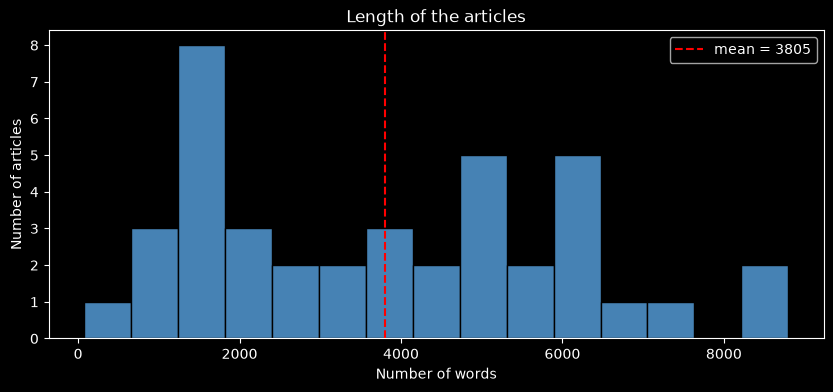

In [45]:
lengths = [len(text.split()) for text in texts]
mean_length = sum(lengths) / len(lengths)

print(f"Average length: {mean_length:.0f} words")
print(f"Shortest: {titles[lengths.index(min(lengths))]} ({min(lengths)} words)")
print(f"Longest: {titles[lengths.index(max(lengths))]} ({max(lengths)} words)")

plt.figure(figsize=(10, 4))
plt.hist(lengths, bins=15, color="steelblue", edgecolor="black")
plt.axvline(mean_length, color="red", linestyle="--", label=f"mean = {mean_length:.0f}")
plt.title("Length of the articles")
plt.xlabel("Number of words")
plt.ylabel("Number of articles")
plt.legend()
plt.show()

The lengths are very different: the longest article is more than 100 times longer than the shortest one. We will come back to this in section 5.

### 2.2. Text preprocessing <a class="anchor" id="section_2_2"></a>
A computer sees `Python`, `python` and `python.` as three different words. Before we compare texts, we turn every text into a list of clean words (**tokens**):

1. Convert all letters to lowercase, so `Python` and `python` are the same word.
2. Remove punctuation, so `language.` becomes `language`.
3. Remove **stopwords**: very common words like `is`, `a`, `the`, `of`. They appear in almost every text and do not tell us anything about its topic.

**Assumption (bag of words):** we only look at which words a text contains, not at their order. For example, "dog bites man" and "man bites dog" give the same tokens. This is a simplification, but it is the base of all methods in this notebook.

In [46]:
STOPWORDS = {
    "a", "an", "the", "and", "or", "but", "if", "of", "to", "in", "on", "at", "by", "for", "with",
    "from", "as", "is", "are", "was", "were", "be", "been", "it", "its", "this", "that", "these",
    "those", "which", "who", "what", "can", "has", "have", "had", "not", "also", "such", "s",
}


def tokenize(text):
    words = re.findall(r"[a-z0-9]+", text.lower())
    return [word for word in words if word not in STOPWORDS]


assert tokenize("Python is a high-level, general-purpose programming language.") == [
    "python", "high", "level", "general", "purpose", "programming", "language"
]

documents = [tokenize(text) for text in texts]
print(tokenize("Python's design philosophy emphasizes code readability."))

['python', 'design', 'philosophy', 'emphasizes', 'code', 'readability']


### 3. Baseline: word overlap (Jaccard similarity) <a class="anchor" id="chapter3"></a>
The simplest idea for search: a document is relevant if it has many words in common with the query.

### 3.1. Sets, intersection and union <a class="anchor" id="section_3_1"></a>
A **set** is a collection of unique elements. If we turn a text into a set of words, each word appears only once, no matter how many times it is in the text.

For two sets $A$ and $B$:
- **intersection** $A \cap B$ - the words that are in **both** sets
- **union** $A \cup B$ - **all** words from the two sets, without repetitions
- $|A|$ - the number of elements in $A$

In Python, sets have the same operations: `a & b` is the intersection and `a | b` is the union.

q       = ['database', 'python']
d_2     = ['database', 'fast', 'redis']
q & d_2 = ['database']
q | d_2 = ['database', 'fast', 'python', 'redis']


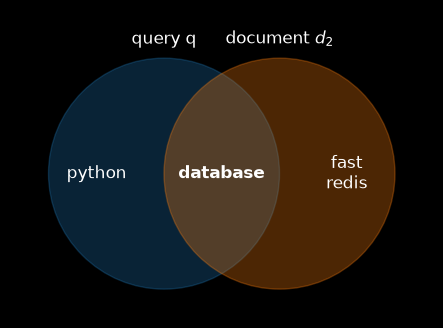

In [47]:
q = set(tokenize("Python database"))
d_2 = set(tokenize("Redis is a fast database"))

print("q       =", sorted(q))
print("d_2     =", sorted(d_2))
print("q & d_2 =", sorted(q & d_2))
print("q | d_2 =", sorted(q | d_2))

fig, ax = plt.subplots(figsize=(7, 4))
ax.add_patch(plt.Circle((-0.6, 0), 1.2, color="tab:blue", alpha=0.3))
ax.add_patch(plt.Circle((0.6, 0), 1.2, color="tab:orange", alpha=0.3))
ax.text(-1.3, 0, "\n".join(sorted(q - d_2)), ha="center", va="center", fontsize=12)
ax.text(0, 0, "\n".join(sorted(q & d_2)), ha="center", va="center", fontsize=12, fontweight="bold")
ax.text(1.3, 0, "\n".join(sorted(d_2 - q)), ha="center", va="center", fontsize=12)
ax.text(-0.6, 1.35, "query q", ha="center", fontsize=12)
ax.text(0.6, 1.35, "document $d_2$", ha="center", fontsize=12)
ax.set_xlim(-2.2, 2.2)
ax.set_ylim(-1.5, 1.7)
ax.set_aspect("equal")
ax.axis("off")
plt.show()

### 3.2. Jaccard similarity <a class="anchor" id="section_3_2"></a>
The **Jaccard similarity** [3] answers the question: *what part of all words are common words?*

$$J(A, B) = \frac{|A \cap B|}{|A \cup B|} \tag{3}$$

**Where:**

$A$ - the set of words in the query $q$

$B$ - the set of words in a document $d_i$

$|A \cap B|$ - number of common words

$|A \cup B|$ - number of all different words in the two texts

We use it as our first scoring function from equation (1): $s(q, d_i) = J(q, d_i)$.

**Special case:** if both sets are empty (for example, a query with only stopwords), the formula becomes $\frac{0}{0}$, which is not defined. Since there are no words, there is no similarity, so we define $J = 0$ in this case.

**Proof that $0 \le J(A, B) \le 1$:**

Every common word is also in the union, so the intersection is a part of the union: $A \cap B \subseteq A \cup B$. Therefore $|A \cap B| \le |A \cup B|$. Both numbers are not negative, so the fraction is between $0$ and $1$. $\blacksquare$

- $J = 0$ when the two texts have no common words.
- $J = 1$ when the two texts have exactly the same set of words.

### 3.3. Implementation <a class="anchor" id="section_3_3"></a>
The function `jaccard` follows equation (3). The function `rank` follows section 1: it computes the score of every document and sorts them in descending order. Python's `sorted` is *stable*, so documents with equal scores keep their original order.

In [48]:
def jaccard(a, b):
    a, b = set(a), set(b)
    union = a | b
    if not union:
        return 0.0
    return len(a & b) / len(union)


def rank(query, documents, score):
    scores = [score(query, document) for document in documents]
    order = sorted(range(len(documents)), key=lambda i: scores[i], reverse=True)
    return [(i, scores[i]) for i in order]

**Check with a hand-computed example.** Query $q$ = "Python database", $d_1$ = "Python is a programming language", $d_2$ = "Redis is a fast database".

After preprocessing: $q = \{python, database\}$, $d_1 = \{python, programming, language\}$, $d_2 = \{redis, fast, database\}$.

$$J(q, d_1) = \frac{|\{python\}|}{|\{python, database, programming, language\}|} = \frac{1}{4} = 0.25$$

$$J(q, d_2) = \frac{|\{database\}|}{|\{python, database, redis, fast\}|} = \frac{1}{4} = 0.25$$

The scores are equal, so $d_1$ stays first because of its original order.

In [49]:
example_query = tokenize("Python database")
example_docs = [tokenize("Python is a programming language"), tokenize("Redis is a fast database")]

assert jaccard(example_query, example_docs[0]) == 0.25
assert jaccard(example_query, example_docs[1]) == 0.25
assert jaccard([], []) == 0.0
assert rank(example_query, example_docs, jaccard) == [(0, 0.25), (1, 0.25)]
print("All checks passed.")

All checks passed.


Now let's search the whole collection:

In [50]:
def show_results(query, score, top=5):
    print(f'Query: "{query}"')
    for position, (i, value) in enumerate(rank(tokenize(query), documents, score)[:top], start=1):
        print(f"{position}. {titles[i]:<35} {groups[i]:<22} score = {value:.4f}")


show_results("python database", jaccard)

Query: "python database"
1. Kibana                              Web & scraping         score = 0.0037
2. Apache Cassandra                    Databases              score = 0.0032
3. Elasticsearch                       Databases              score = 0.0029
4. SQLite                              Databases              score = 0.0025
5. SQL                                 Programming languages  score = 0.0025


The result is surprising: **Kibana** is first, and the article about **Python** is not in the top 5. Let's look at the numbers:

In [51]:
query = set(tokenize("python database"))
for title in ["Kibana", "Apache Cassandra", "Python (programming language)"]:
    i = titles.index(title)
    document = set(documents[i])
    position = [j for j, _ in rank(list(query), documents, jaccard)].index(i) + 1
    print(f"{title:<32} common words: {sorted(query & document)}, "
          f"different words: {len(document)}, position: {position}")

Kibana                           common words: ['database'], different words: 269, position: 1
Apache Cassandra                 common words: ['database', 'python'], different words: 619, position: 2
Python (programming language)    common words: ['python'], different words: 1590, position: 30


Long articles have many different words, so the union $|A \cup B|$ in equation (3) is very big and the score becomes very small. Kibana has only one of the two query words, but it is a short article, so it wins. The Python article has more than 1500 different words and it is only at position 30.

So Jaccard has three problems:
1. It prefers **short documents**.
2. Every word has the **same weight**. A rare word like `redis` counts the same as a common word like `data`.
3. It does not count **how many times** a word appears in the text.

In the next section we will see how TF-IDF solves problems 2 and 3. Problem 1 (the length of the documents) will be discussed in section 5 with cosine similarity.

### 4. TF-IDF <a class="anchor" id="chapter4"></a>
TF-IDF (term frequency - inverse document frequency) [4] gives every word a **weight**. The idea is simple:
- a word is important for a document if it appears **many times** in this document (TF);
- a word is important in general if it appears in **few documents** (IDF).

We will use this small example in sections 4.1 - 4.3:

In [52]:
mini_texts = [
    "Python code and Python data",
    "Redis stores data",
    "Python reads data from Redis",
]
mini_docs = [tokenize(text) for text in mini_texts]
for i, doc in enumerate(mini_docs, start=1):
    print(f"d_{i} = {doc}")

d_1 = ['python', 'code', 'python', 'data']
d_2 = ['redis', 'stores', 'data']
d_3 = ['python', 'reads', 'data', 'redis']


### 4.1. Term frequency (TF) <a class="anchor" id="section_4_1"></a>
If a word appears many times in a text, the text is probably about it. The **term frequency** is simply how many times the word appears in the document:

$$tf(t, d) = \text{number of times the word } t \text{ appears in the document } d \tag{4}$$

**Where:**

$t$ - a word (term)

$d$ - a document

For example, the word `python` appears 2 times in $d_1$, so $tf(python, d_1) = 2$. Unlike Jaccard, TF counts repetitions, so it solves problem 3 from section 3.

In [53]:
def tf(term, document):
    return document.count(term)


assert tf("python", mini_docs[0]) == 2
assert tf("redis", mini_docs[0]) == 0
assert tf("data", mini_docs[1]) == 1
print("All checks passed.")

All checks passed.


### 4.2. Inverse document frequency (IDF) and logarithms <a class="anchor" id="section_4_2"></a>
TF alone is not enough. The word `data` appears in all three documents, so it does not help us to find the right one. A word like `code` appears only in $d_1$, so it tells us a lot. We need a number which is **big for rare words** and **small for common words**.

The **document frequency** $df(t)$ is the number of documents which contain the word $t$. The ratio $\frac{N}{df(t)}$ is big for rare words: for a word in 1 of 40 documents it is $40$, and for a word in all 40 documents it is $1$.

**Logarithms.** The ratio can grow very fast, so we make it smaller with a logarithm. The logarithm answers the question *"to which power do I need to raise the base to get this number?"* For example, $10^2 = 100$, so $\log_{10} 100 = 2$. We use the **natural logarithm** $\ln$, whose base is the number $e \approx 2.718$. Two properties are important for us:
- $\ln 1 = 0$, because $e^0 = 1$;
- $\ln$ is **increasing**: a bigger number has a bigger logarithm.

The **inverse document frequency** is:

$$idf(t) = \ln \frac{N}{df(t)} \tag{5}$$

**Where:**

$N$ - number of documents

$df(t)$ - number of documents which contain the word $t$

**Assumption:** we use only words which appear in at least one document, so $df(t) \ge 1$ and we never divide by zero. A query word which is not in the collection is ignored (its weight is $0$).

**Proof 1: a word in every document has $idf = 0$.**

If the word is in all documents, then $df(t) = N$, so $idf(t) = \ln \frac{N}{N} = \ln 1 = 0$. $\blacksquare$

This is why `data` will not help the ranking: its weight is zero.

**Proof 2: $idf(t) \ge 0$, and the more documents contain a word, the smaller its idf.**

A word cannot be in more documents than we have, so $1 \le df(t) \le N$ and $\frac{N}{df(t)} \ge 1$. Since $\ln$ is increasing and $\ln 1 = 0$, we get $idf(t) \ge 0$. If $df(t)$ grows, the ratio $\frac{N}{df(t)}$ becomes smaller, and because $\ln$ is increasing, $idf(t)$ also becomes smaller. $\blacksquare$

In [54]:
def df(term, documents):
    return sum(1 for document in documents if term in document)


def idf(term, documents):
    return np.log(len(documents) / df(term, documents))


assert df("data", mini_docs) == 3
assert df("python", mini_docs) == 2
assert df("code", mini_docs) == 1
assert idf("data", mini_docs) == 0
assert np.isclose(idf("python", mini_docs), np.log(3 / 2))
assert np.isclose(idf("code", mini_docs), np.log(3))

for term in ["data", "python", "redis", "code"]:
    print(f"{term:<8} df = {df(term, mini_docs)}   idf = ln(3/{df(term, mini_docs)}) = {idf(term, mini_docs):.3f}")

data     df = 3   idf = ln(3/3) = 0.000
python   df = 2   idf = ln(3/2) = 0.405
redis    df = 2   idf = ln(3/2) = 0.405
code     df = 1   idf = ln(3/1) = 1.099


The plot shows equation (5) for our collection of $N = 40$ articles. A word which appears in only one article gets the highest weight, and a word which appears in all articles gets weight $0$:

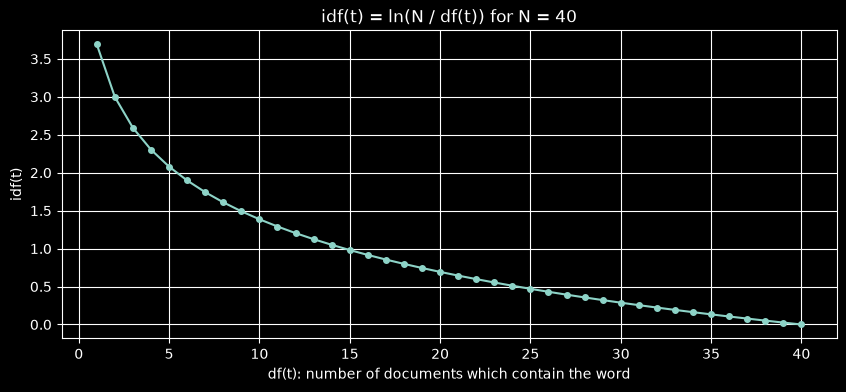

In [55]:
n_documents = len(documents)
df_values = np.arange(1, n_documents + 1)
idf_values = np.log(n_documents / df_values)

plt.figure(figsize=(10, 4))
plt.plot(df_values, idf_values, marker="o", markersize=4)
plt.title(f"idf(t) = ln(N / df(t)) for N = {n_documents}")
plt.xlabel("df(t): number of documents which contain the word")
plt.ylabel("idf(t)")
plt.grid()
plt.show()

In [56]:
document_sets = [set(document) for document in documents]
for term in ["redis", "python", "database", "language", "software"]:
    print(f"{term:<10} df = {df(term, document_sets):>2}   idf = {idf(term, document_sets):.3f}")

redis      df =  2   idf = 2.996
python     df = 20   idf = 0.693
database   df = 26   idf = 0.431
language   df = 35   idf = 0.134
software   df = 40   idf = 0.000


On the real articles, `redis` is a rare word (only 2 articles) and gets a high idf. The word `software` appears in all 40 articles and gets $0$: in a collection about technology, it does not help us to find a specific article. This solves problem 2 from section 3: words have different weights now.


### 4.3. TF-IDF weights: a hand-computed example <a class="anchor" id="section_4_3"></a>
Now we put the two ideas together. The weight of a word in a document is:

$$w(t, d) = tf(t, d) \cdot idf(t) \tag{6}$$

**Where:**

$w(t, d)$ - the TF-IDF weight of the word $t$ in the document $d$

$tf(t, d)$ - term frequency from equation (4)

$idf(t)$ - inverse document frequency from equation (5)

A word gets a high weight if it appears **many times** in this document **and** in **few** other documents.

Let's compute all weights for our small example by hand. From section 4.2 we know: $idf(data) = \ln \frac{3}{3} = 0$, $idf(python) = idf(redis) = \ln \frac{3}{2} \approx 0.405$, and $idf(code) = idf(reads) = idf(stores) = \ln 3 \approx 1.099$.

| | code | data | python | reads | redis | stores |
|:-:|:-:|:-:|:-:|:-:|:-:|:-:|
| $d_1$ | $1 \cdot 1.099 = 1.099$ | $1 \cdot 0 = 0$ | $2 \cdot 0.405 = 0.811$ | $0$ | $0$ | $0$ |
| $d_2$ | $0$ | $1 \cdot 0 = 0$ | $0$ | $0$ | $1 \cdot 0.405 = 0.405$ | $1 \cdot 1.099 = 1.099$ |
| $d_3$ | $0$ | $1 \cdot 0 = 0$ | $1 \cdot 0.405 = 0.405$ | $1 \cdot 1.099 = 1.099$ | $1 \cdot 0.405 = 0.405$ | $0$ |

Two things to notice:
- The column `data` is all zeros. The word is in every document, so it does not help to tell them apart.
- `python` has a bigger weight in $d_1$ than in $d_3$, because it appears there two times.

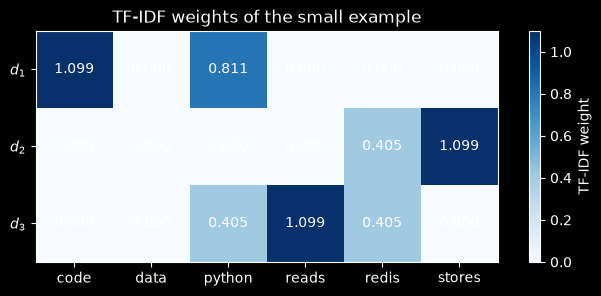

In [57]:
def tfidf(term, document, documents):
    """TF-IDF weight of a word in a document, equation (6)."""
    return tf(term, document) * idf(term, documents)


vocabulary = sorted(set(word for document in mini_docs for word in document))
weights = np.array([[tfidf(term, document, mini_docs) for term in vocabulary] for document in mini_docs])

assert vocabulary == ["code", "data", "python", "reads", "redis", "stores"]
assert np.allclose(weights[:, 1], 0)
assert np.isclose(weights[0, 2], 2 * np.log(3 / 2))
assert np.isclose(weights[2, 2], np.log(3 / 2))
assert np.isclose(weights[1, 5], np.log(3))

plt.figure(figsize=(8, 3))
plt.imshow(weights, cmap="Blues")
plt.colorbar(label="TF-IDF weight")
plt.xticks(range(len(vocabulary)), vocabulary)
plt.yticks(range(len(mini_docs)), ["$d_1$", "$d_2$", "$d_3$"])
for i in range(weights.shape[0]):
    for j in range(weights.shape[1]):
        plt.text(j, i, f"{weights[i, j]:.3f}", ha="center", va="center")
plt.title("TF-IDF weights of the small example")
plt.show()

### 4.4. Implementation <a class="anchor" id="section_4_4"></a>
The functions above are good for learning, but they are slow: `idf` counts the documents again for every word. For the real articles we compute the idf of every word **only once** and save it in a dictionary.

Most words of the vocabulary are not in a given document, so most weights are $0$. We save only the words with a weight in a dictionary `{word: weight}`. In section 5 we will see this dictionary as a **vector**.

As promised in section 4.2, a word which is not in the collection has no idf, so it gets weight $0$ and is ignored.

In [58]:
def compute_idf(documents):
    """Idf of every word in the collection, equation (5)."""
    document_frequency = Counter(word for document in documents for word in set(document))
    n = len(documents)
    return {word: np.log(n / count) for word, count in document_frequency.items()}


def tfidf_vector(document, idf_values):
    """TF-IDF weights of all words in a document. Unknown words are ignored."""
    counts = Counter(document)
    return {word: count * idf_values[word] for word, count in counts.items() if word in idf_values}


# Check: the fast version gives the same results as the functions from 4.1 - 4.3
mini_idf = compute_idf(mini_docs)
for document in mini_docs:
    vector = tfidf_vector(document, mini_idf)
    for term in vocabulary:
        assert np.isclose(vector.get(term, 0), tfidf(term, document, mini_docs))

# Check: unknown words are ignored
assert tfidf_vector(["python", "blockchain"], mini_idf) == {"python": mini_idf["python"]}
print("All checks passed.")

All checks passed.


Now we compute the TF-IDF vectors of all 40 articles. If TF-IDF works, the words with the highest weight should describe the topic of each article:

In [59]:
idf_values = compute_idf(documents)
tfidf_vectors = [tfidf_vector(document, idf_values) for document in documents]

print(f"Vocabulary: {len(idf_values)} different words\n")
for title in ["Redis", "Python (programming language)", "Kibana", "Web scraping"]:
    vector = tfidf_vectors[titles.index(title)]
    top_words = sorted(vector.items(), key=lambda item: (-item[1], item[0]))[:5]
    print(f"{title:<32}", ", ".join(f"{word} ({weight:.1f})" for word, weight in top_words))

Vocabulary: 10676 different words

Redis                            redis (203.7), sanfilippo (36.9), ltd (15.0), salvatore (14.8), license (13.7)
Python (programming language)    python (168.4), cpython (47.9), division (41.4), pep (36.9), rossum (36.9)
Kibana                           kibana (56.9), elastic (41.6), elasticsearch (41.4), visualization (18.0), logstash (15.0)
Web scraping                     scraping (119.8), court (44.0), qvc (40.6), bots (35.9), farechase (25.8)


For every article, the first word is the name of the topic: `redis`, `python`, `kibana`, `scraping`. So TF-IDF finds the main word of each text without any help from us.

The other top words are also interesting. Many of them are names of people and companies (`sanfilippo` and `salvatore` - the creator of Redis, `rossum` - the creator of Python) or companies from court cases about scraping (`qvc`, `farechase`). These words appear in only one article, so their idf is high, even if they are not the most important words for the topic. This is a known side effect of IDF: rare words get high weights.


### 5. Cosine similarity <a class="anchor" id="chapter5"></a>
TF-IDF gives us a weight for every word in every document. But we still need a **score** $s(q, d_i)$ from equation (1): one number which tells us how similar a document is to the query. For this we look at texts as **vectors** and measure the **angle** between them [5].

### 5.1. Documents as vectors <a class="anchor" id="section_5_1"></a>
Let's give every word of the vocabulary its own axis. Then every document is a list of numbers (its TF-IDF weights), and this list is a **vector**. Our small example has 6 words, so each document is a vector with 6 numbers. These are the rows of the table in section 4.3:

$$d_1 = (1.099,\ 0,\ 0.811,\ 0,\ 0,\ 0)$$

$$d_2 = (0,\ 0,\ 0,\ 0,\ 0.405,\ 1.099)$$

$$d_3 = (0,\ 0,\ 0.405,\ 1.099,\ 0.405,\ 0)$$

The query is also a short text, so it is a vector too. For $q$ = "Python Redis" we get $q = (0,\ 0,\ 0.405,\ 0,\ 0.405,\ 0)$.

We cannot draw 6 dimensions, but we can draw 2. Let's take only two words, `python` and `redis`, and three texts: $a$ uses `python` 3 times and `redis` once, $b$ uses `python` once and `redis` 3 times, and $c$ is the text $a$ written two times. Each text is an arrow:

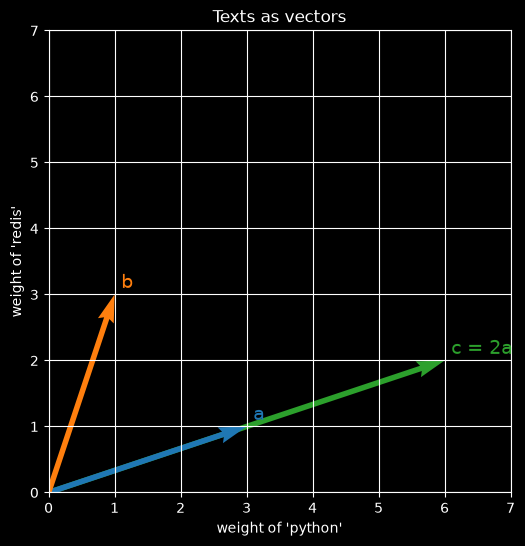

In [60]:
a = np.array([3, 1])
b = np.array([1, 3])
c = 2 * a

plt.figure(figsize=(6, 6))
for vector, name, color in [(c, "c = 2a", "tab:green"), (a, "a", "tab:blue"), (b, "b", "tab:orange")]:
    plt.quiver(0, 0, vector[0], vector[1], angles="xy", scale_units="xy", scale=1, color=color, width=0.012)
    plt.text(vector[0] + 0.1, vector[1] + 0.1, name, fontsize=14, color=color)
plt.xlim(0, 7)
plt.ylim(0, 7)
plt.xlabel("weight of 'python'")
plt.ylabel("weight of 'redis'")
plt.title("Texts as vectors")
plt.grid()
plt.gca().set_aspect("equal")
plt.show()

The arrows $a$ and $c$ point in the **same direction**: they talk about the same things in the same proportion. The arrow $b$ points in another direction. So the **direction** of a vector shows what a text is about, and the **angle** between two vectors shows how different two texts are.

### 5.2. Dot product and vector length <a class="anchor" id="section_5_2"></a>
To compute the angle, we need two tools. The **dot product** multiplies the weights of the same word and adds everything:

$$a \cdot b = \sum_{j=1}^{V} a_j b_j \tag{7}$$

The **length** (norm) of a vector is its distance from the point $(0, 0, \dots, 0)$. This is the Pythagorean theorem in many dimensions:

$$\|a\| = \sqrt{\sum_{j=1}^{V} a_j^2} \tag{8}$$

**Where:**

$V$ - number of words in the vocabulary (number of axes)

$a_j$, $b_j$ - the weight of the $j$-th word in the vectors $a$ and $b$

The dot product is big when the two texts have **big weights for the same words**. If two texts have no common words, every product $a_j b_j$ has a zero, so $a \cdot b = 0$.

For example, $a \cdot b = 3 \cdot 1 + 1 \cdot 3 = 6$ and $\|a\| = \sqrt{3^2 + 1^2} = \sqrt{10} \approx 3.162$.

In [61]:
def dot(a, b):
    """Dot product, equation (7)."""
    return sum(a_j * b_j for a_j, b_j in zip(a, b))


def length(a):
    """Length of a vector, equation (8)."""
    return np.sqrt(sum(a_j ** 2 for a_j in a))


assert dot(a, b) == 6
assert np.isclose(length(a), np.sqrt(10))
assert dot(a, b) == np.dot(a, b) and np.isclose(length(a), np.linalg.norm(a))
print("All checks passed.")

All checks passed.


### 5.3. The angle between two vectors <a class="anchor" id="section_5_3"></a>
From geometry, the dot product and the angle $\theta$ between two vectors are connected [5]: $a \cdot b = \|a\| \, \|b\| \cos \theta$. So the cosine of the angle is:

$$\cos(a, b) = \frac{a \cdot b}{\|a\| \, \|b\|} \tag{9}$$

This is the **cosine similarity**, our second scoring function: $s(q, d_i) = \cos(q, d_i)$.

- same direction: $\theta = 0°$ and $\cos = 1$
- no common words: $a \cdot b = 0$, so $\theta = 90°$ and $\cos = 0$

**Special case:** if a vector has length $0$ (for example, a query with only unknown words or stopwords), we divide by zero. Like with Jaccard, there are no words, so there is no similarity, and we define $\cos = 0$.

**Proof 1: for TF-IDF vectors, $0 \le \cos(a, b) \le 1$.**

All TF-IDF weights are $\ge 0$, because $tf \ge 0$ and $idf \ge 0$ (proof 2 in section 4.2). So every product $a_j b_j \ge 0$, the dot product is $\ge 0$, and $\cos(a, b) \ge 0$. The **Cauchy-Schwarz inequality** [6] says that $a \cdot b \le \|a\| \, \|b\|$, so $\cos(a, b) \le 1$. $\blacksquare$

**Proof 2: the length of a vector does not change the cosine.**

Let $k > 0$ be a number. Then $q \cdot (k d) = k \, (q \cdot d)$ and $\|k d\| = k \, \|d\|$. So:

$$\cos(q, k d) = \frac{k \, (q \cdot d)}{\|q\| \cdot k \, \|d\|} = \frac{q \cdot d}{\|q\| \, \|d\|} = \cos(q, d) \quad \blacksquare$$

This means: if we write the same text two times, all its TF values are doubled, but its score stays the same. Only the **direction** matters, not the length. This helps with problem 1 from section 3, but it does not solve it completely: two **different** texts of different length can still get different scores. We will come back to this in section 6.

In [62]:
def cosine(a, b):
    """Cosine similarity, equation (9). Returns 0 for an empty vector."""
    if length(a) == 0 or length(b) == 0:
        return 0.0
    return dot(a, b) / (length(a) * length(b))


print(f"cos(a, b) = {cosine(a, b):.3f}  ->  angle = {np.degrees(np.arccos(cosine(a, b))):.1f} degrees")
print(f"cos(a, c) = {cosine(a, c):.3f}  ->  same direction")

assert np.isclose(cosine(a, b), 0.6)
assert np.isclose(cosine(a, c), 1)
assert cosine(a, np.array([0, 0])) == 0.0

cos(a, b) = 0.600  ->  angle = 53.1 degrees
cos(a, c) = 1.000  ->  same direction


**Check with a hand-computed example.** Let's compute $\cos(q, d_3)$ for $q$ = "Python Redis" from section 5.1. The common words are `python` and `redis`:

$$q \cdot d_3 = 0.405 \cdot 0.405 + 0.405 \cdot 0.405 \approx 0.329$$

$$\|q\| = \sqrt{0.405^2 + 0.405^2} \approx 0.573, \qquad \|d_3\| = \sqrt{0.405^2 + 1.099^2 + 0.405^2} \approx 1.239$$

$$\cos(q, d_3) = \frac{0.329}{0.573 \cdot 1.239} \approx 0.463$$

In the same way we get $\cos(q, d_1) \approx 0.420$ and $\cos(q, d_2) \approx 0.245$. So the ranking is $d_3, d_1, d_2$. This makes sense: $d_3$ contains both query words, $d_1$ contains `python` two times, and $d_2$ contains only `redis`.

In [63]:
mini_query = np.array([tfidf(term, tokenize("Python Redis"), mini_docs) for term in vocabulary])
mini_scores = [cosine(mini_query, weights[i]) for i in range(len(mini_docs))]

for i, value in enumerate(mini_scores, start=1):
    print(f"cos(q, d_{i}) = {value:.3f}")

assert np.round(mini_scores, 3).tolist() == [0.420, 0.245, 0.463]

cos(q, d_1) = 0.420
cos(q, d_2) = 0.245
cos(q, d_3) = 0.463


### 5.4. Why not the Euclidean distance? <a class="anchor" id="section_5_4"></a>
A natural idea is to use the **Euclidean distance** between two vectors: the length of the line between their ends. It is the distance between two points from school, written for many dimensions:

$$dist(a, b) = \|a - b\| = \sqrt{\sum_{j=1}^{V} (a_j - b_j)^2} \tag{10}$$

A small distance means similar texts. But look at our three arrows from section 5.1:

In [64]:
def euclidean(a, b):
    """Euclidean distance, equation (10)."""
    return length(a - b)


print(f"dist(a, b) = {euclidean(a, b):.3f}    cos(a, b) = {cosine(a, b):.3f}")
print(f"dist(a, c) = {euclidean(a, c):.3f}    cos(a, c) = {cosine(a, c):.3f}")

assert euclidean(a, c) > euclidean(a, b)

dist(a, b) = 2.828    cos(a, b) = 0.600
dist(a, c) = 3.162    cos(a, c) = 1.000


The text $c$ is the text $a$ written two times, so it is about **exactly the same thing**. But the Euclidean distance says that $b$ is **closer** to $a$ than $c$ ($2.828 < 3.162$). The distance changes when a text becomes longer, because the end of the arrow moves. The cosine looks only at the direction, so it correctly says that $a$ and $c$ are the same ($\cos = 1$). This is why the vector space model uses the cosine and not the Euclidean distance to compare TF-IDF vectors [5].

### 5.5. Ranking the articles with cosine similarity <a class="anchor" id="section_5_5"></a>
In section 4.4 we stored every article as a dict `{word: weight}`. Each article uses only a small part of the 10676 words, so a list with 10676 numbers would be almost all zeros. The formula is still equation (9). In the dot product we only add the words which are in **both** dicts, because for every other word one of the two weights is 0, and $0 \cdot x = 0$.

In [65]:
def cosine_sparse(a, b):
    """Cosine similarity, equation (9), for vectors stored as dicts."""
    dot_product = sum(weight * b[word] for word, weight in a.items() if word in b)
    length_a = length(list(a.values()))
    length_b = length(list(b.values()))
    if length_a == 0 or length_b == 0:
        return 0.0
    return dot_product / (length_a * length_b)


def tfidf_cosine(query, document):
    """Score of a document: the cosine between the TF-IDF vectors of the query and the document."""
    return cosine_sparse(tfidf_vector(query, idf_values), tfidf_vector(document, idf_values))


mini_idf = compute_idf(mini_docs)
mini_query_dict = tfidf_vector(tokenize("Python Redis"), mini_idf)
mini_scores_dict = [cosine_sparse(mini_query_dict, tfidf_vector(document, mini_idf)) for document in mini_docs]

assert np.allclose(mini_scores_dict, mini_scores)
assert tfidf_cosine(tokenize("the"), documents[0]) == 0.0
print("All checks passed.")

All checks passed.


The first check shows that the dict version gives the same scores as the array version from section 5.3. The second one is a query with only a stopword: its vector is empty, so the score is 0.

Now we search the whole collection with the same query as in section 3.3:

In [66]:
show_results("python database", tfidf_cosine)

Query: "python database"
1. Python (programming language)       Programming languages  score = 0.5654
2. Oracle Database                     Databases              score = 0.1426
3. PostgreSQL                          Databases              score = 0.0637
4. Relational database                 Databases              score = 0.0570
5. SQL                                 Programming languages  score = 0.0475


This looks much better than Jaccard. **Python** is first with a clear lead, and the next four articles are about databases and SQL. With Jaccard, Kibana was first and the Python article was only 30th.

Why? Jaccard only checks if a word is present or not. TF-IDF + cosine also looks at **how often** a word is used and **how rare** it is. The Python article uses the word `python` very often (it is its top word in section 4.4), so its vector points almost in the same direction as the query. Also, `python` is rarer than `database` (idf 0.693 vs 0.431), so it counts more.

The document length problem is not fully solved by the cosine, as we said in section 5.3. We will come back to it in section 6 with BM25.

### 5.6. Checking our code with scikit-learn <a class="anchor" id="section_5_6"></a>
scikit-learn [7] is a popular Python library for machine learning. Its class `TfidfVectorizer` computes TF-IDF vectors, so we can use it to check our own code. But it uses a slightly different formula, and we must understand the differences first [7]:

**1. It adds 1 to the idf.** With the option `smooth_idf=False`:

$$idf_{sk}(t) = \ln \frac{N}{df(t)} + 1 \tag{11}$$

(The default `smooth_idf=True` also adds 1 inside the fraction.) Because of the +1, a word which is in every document gets $idf_{sk} = 1$ and not 0 as in Proof 1 of section 4.2. So it is not completely ignored.

**2. It divides every vector by its length** (this is called **L2 normalization**):

$$\hat{d} = \frac{d}{\|d\|} \tag{12}$$

Where:
- $d$ is the TF-IDF vector of a document
- $\|d\|$ is its length, equation (8)
- $\hat{d}$ is the new vector, with length 1

After this, the cosine (9) is just the dot product, because $\cos(\hat{q}, \hat{d}) = \frac{\hat{q} \cdot \hat{d}}{1 \cdot 1}$. And because of Proof 2 in section 5.3, dividing a vector by a positive number does not change its cosine with other vectors.

So we give sklearn our tokenizer (`analyzer=tokenize`), turn off the smoothing, and compare its result with our own vectors, built with $idf + 1$ and divided by their length:

In [67]:
vectorizer = TfidfVectorizer(analyzer=tokenize, smooth_idf=False)
sklearn_matrix = vectorizer.fit_transform(texts).toarray()

idf_plus_one = {word: value + 1 for word, value in idf_values.items()}
our_matrix = np.zeros(sklearn_matrix.shape)
for i, document in enumerate(documents):
    vector = tfidf_vector(document, idf_plus_one)
    vector_length = length(list(vector.values()))
    for word, weight in vector.items():
        our_matrix[i, vectorizer.vocabulary_[word]] = weight / vector_length

assert len(vectorizer.vocabulary_) == len(idf_values)
assert vectorizer.idf_[vectorizer.vocabulary_["software"]] == 1.0
assert np.abs(our_matrix - sklearn_matrix).max() < 1e-12
print(f"Matrix size: {sklearn_matrix.shape[0]} articles x {sklearn_matrix.shape[1]} words")
print("Our vectors and the sklearn vectors are the same.")

Matrix size: 40 articles x 10676 words
Our vectors and the sklearn vectors are the same.


The vocabulary is the same, the word `software` (in all 40 articles) gets $idf_{sk} = 1$, and all $40 \cdot 10676$ numbers are equal. So our TF-IDF code works correctly.

Now let's rank with the sklearn vectors. All rows have length 1, so the scores are simply dot products:

In [68]:
sklearn_query = vectorizer.transform(["python database"]).toarray()[0]
sklearn_scores = sklearn_matrix @ sklearn_query
order = sorted(range(len(texts)), key=lambda i: sklearn_scores[i], reverse=True)

print('Query: "python database" (sklearn, idf + 1)')
for position, i in enumerate(order[:5], start=1):
    print(f"{position}. {titles[i]:<35} {groups[i]:<22} score = {sklearn_scores[i]:.4f}")

Query: "python database" (sklearn, idf + 1)
1. Python (programming language)       Programming languages  score = 0.5893
2. Oracle Database                     Databases              score = 0.3008
3. PostgreSQL                          Databases              score = 0.1393
4. Relational database                 Databases              score = 0.1354
5. SQLite                              Databases              score = 0.0989


The first four articles are the same as with our formula, but the scores are different and the 5th place changes (SQLite instead of SQL). The reason is the +1 in equation (11). The idf of `database` becomes 1.431 instead of 0.431, and the idf of `python` becomes 1.693 instead of 0.693. So the common word `database` is now almost as important as `python`, and the database articles get higher scores.

Both versions are correct. They are just two different choices. In this project we keep the textbook formula (5).

### 6. BM25 <a class="anchor" id="chapter6"></a>

_TODO_

### 7. Experiments <a class="anchor" id="chapter7"></a>

_TODO_

### 8. Limitations <a class="anchor" id="chapter8"></a>

_TODO_

### 9. Conclusion <a class="anchor" id="chapter9"></a>

_TODO_

### 10. References <a class="anchor" id="chapter10"></a>
1. Wikipedia, The Free Encyclopedia - 40 articles, listed in `data/articles.json`. Licensed under [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/). Retrieved 2026-10-23.
2. [MediaWiki Action API](https://www.mediawiki.org/wiki/API:Main_page)
3. Paul Jaccard - "Étude comparative de la distribution florale dans une portion des Alpes et du Jura", Bulletin de la Société Vaudoise des Sciences Naturelles, 1901; <a href="https://en.wikipedia.org/wiki/Jaccard_index">Wikipedia - Jaccard index</a>
4. Karen Spärck Jones - "A statistical interpretation of term specificity and its application in retrieval", Journal of Documentation, 1972; <a href="https://en.wikipedia.org/wiki/Tf%E2%80%93idf">Wikipedia - tf-idf</a>
5. Christopher D. Manning, Prabhakar Raghavan, Hinrich Schütze - "Introduction to Information Retrieval", Cambridge University Press, 2008, chapter 6 "Scoring, term weighting and the vector space model"; <a href="https://nlp.stanford.edu/IR-book/">online version</a>
6. <a href="https://en.wikipedia.org/wiki/Cauchy%E2%80%93Schwarz_inequality">Wikipedia - Cauchy-Schwarz inequality</a>
7. Fabian Pedregosa et al. - "Scikit-learn: Machine Learning in Python", Journal of Machine Learning Research 12, 2011; <a href="https://scikit-learn.org/stable/modules/feature_extraction.html#tfidf-term-weighting">scikit-learn User Guide - Tf-idf term weighting</a>

**Tools used:** I used LLMs (Claude, ChatGPT and Gemini) to help me understand the concepts, explain the main ideas, and write and review the text and code.
